# CELLxGENE scRNA-seq reference for spatial transcriptomics scoring

## Museum of Spatial Transcriptomics integration

Spatial datasets from the public Museum of Spatial Transcriptomics Google Sheet are normalized into the same dataset-level schema and appended to `spatial_meta` before reference scoring. These rows are spatial-query datasets only; they are not treated as sc/snRNA reference candidates.


In [1]:
import cellxgene_census
import pandas as pd
import numpy as np

OBS_COLS = [
    "dataset_id",
    "assay",
    "cell_type",
    "tissue",
    "tissue_general",
    "disease",
    "suspension_type",
    "donor_id",
    "is_primary_data",
    "n_measured_vars",
]

with cellxgene_census.open_soma() as census:
    datasets = (
        census["census_info"]["datasets"]
        .read()
        .concat()
        .to_pandas()
    )

    organism_obs = []

    for organism in census["census_data"].keys():
        print(f"Reading obs metadata for {organism}")

        obs = (
            census["census_data"][organism]
            .obs
            .read(column_names=OBS_COLS,value_filter="is_primary_data == True")
            .concat()
            .to_pandas()
        )

        obs["organism"] = organism
        obs = obs[obs['is_primary_data'].fillna(False)].copy()
        organism_obs.append(obs)
cell_meta = pd.concat(organism_obs, ignore_index=True)

summary = (
    cell_meta
    .groupby("dataset_id")
    .agg(
        n_cells=("dataset_id", "size"),
        assays=("assay", lambda x: sorted(x.dropna().unique())),
        tissues=("tissue", lambda x: sorted(x.dropna().unique())),
        tissue_general=("tissue_general", lambda x: sorted(x.dropna().unique())),
        diseases=("disease", lambda x: sorted(x.dropna().unique())),
        cell_types=("cell_type", lambda x: sorted(x.dropna().unique())),
        organisms=("organism", lambda x: sorted(x.dropna().unique())),
        suspension_types=("suspension_type", lambda x: sorted(x.dropna().unique())),
        n_donors=("donor_id", lambda x: x.dropna().nunique()),
        median_n_measured_vars=("n_measured_vars", "median"),
    )
    .reset_index()
)

summary = summary.merge(
    datasets,
    on="dataset_id",
    how="inner",   # important: avoid metadata-only rows with no obs rows
)

summary["source_database"] = "cellxgene"

The "stable" release is currently 2025-11-08. Specify 'census_version="2025-11-08"' in future calls to open_soma() to ensure data consistency.


Reading obs metadata for callithrix_jacchus
Reading obs metadata for homo_sapiens
Reading obs metadata for macaca_mulatta
Reading obs metadata for mus_musculus
Reading obs metadata for pan_troglodytes


In [3]:
summary.to_csv('cellxgene_meta.csv')

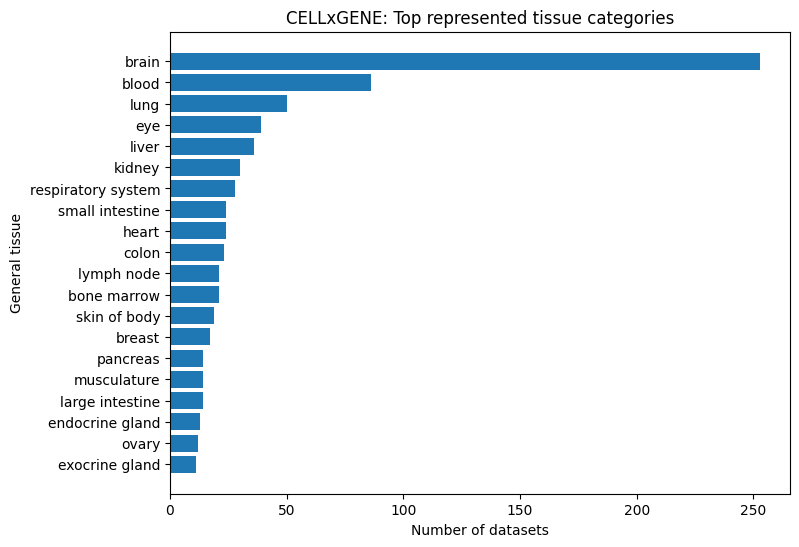

In [3]:
import matplotlib.pyplot as plt
def explode_list_column(df, col):
    tmp = df[["dataset_id", col]].copy()
    tmp[col] = tmp[col].apply(lambda x: x if isinstance(x, list) else [])
    return tmp.explode(col).dropna()

tissue_counts = (
    explode_list_column(summary, "tissue_general")
    .query("tissue_general != ''")
    .groupby("tissue_general")
    .size()
    .sort_values(ascending=False)
    .head(20)
    .sort_values()
)

plt.figure(figsize=(8, 6))
plt.barh(tissue_counts.index, tissue_counts.values)
plt.xlabel("Number of datasets")
plt.ylabel("General tissue")
plt.title("CELLxGENE: Top represented tissue categories")
plt.show()

In [4]:
def preview_list(x, n=4):
    if not isinstance(x, list):
        return x
    if len(x) <= n:
        return ", ".join(map(str, x))
    return ", ".join(map(str, x[:n])) + f", ... ({len(x)} total)"

display_cols = [
    "dataset_id",
    "collection_id",
    "collection_name",
    "dataset_title",
    "n_cells",
    "assays",
    "tissues",
    "tissue_general",
    "diseases",
    "suspension_types",
    "n_donors",
    "median_n_measured_vars",
]

summary_display = summary.copy()
for col in ["assays", "tissues", "tissue_general", "diseases", "suspension_types", "cell_types"]:
    summary_display[col] = summary_display[col].apply(preview_list)

summary_display[display_cols].sort_values("n_cells", ascending=False).head(20)

,dataset_id,collection_id,collection_name,dataset_title,n_cells,assays,tissues,tissue_general,diseases,suspension_types,n_donors,median_n_measured_vars
549,dcfd4feb-18a3-4b30-81d7-1b0c544a8ab3,45d5d2c3-bc28-4814-aed6-0bb6f0e11c82,A single-cell transcriptional timelapse of mou...,Whole dataset: Raw counts only,11441407,sci-RNA-seq3,embryo,embryo,normal,nucleus,74,45525.0
143,37a17b78-4864-4a42-b67b-31c00962795a,84ce6837-548d-4a1f-919f-0bc0d9a3952f,Population-scale cross-disorder atlas of the h...,MSSM_Cohort,4140453,10x 3' v3,dorsolateral prefrontal cortex,brain,"Lewy body dementia, Parkinson disease, amyotro...",nucleus,1042,34176.0
627,f7c1c579-2dc0-47e2-ba19-8165c5a0e353,c114c20f-1ef4-49a5-9c2e-d965787fb90c,A human cell atlas of fetal gene expression,Survey of human embryonic development,4062980,sci-RNA-seq3,"adrenal gland, cerebellum, eye, heart, ... (15...","adrenal gland, brain, endocrine gland, eye, .....","normal, trisomy 18","cell, nucleus",28,45676.0
528,d6505c89-c43d-4c28-8c4f-7351a5fd5528,4c6eaf5c-6d57-4c76-b1e9-60df8c655f1e,Single cell atlas of the human retina,snRNA-seq of human retina - all cells,2907910,10x 3' v3,"fovea centralis, macula lutea, macula lutea pr...",eye,normal,nucleus,100,35475.0
188,46104f0b-9af5-466a-ae0f-56b8dc1969a2,e9360edf-b0b7-4e01-bce8-e596814f13e7,Multi-omic profiling reveals age-related immun...,"Sound Life Young Adult Females, CMV-negative",2616824,10x 3' v3,blood,blood,normal,cell,18,32357.0
430,aa32098f-f7b0-43f2-a00a-601d190aae94,e9360edf-b0b7-4e01-bce8-e596814f13e7,Multi-omic profiling reveals age-related immun...,"Sound Life Older Adult Females, CMV-positive",2596111,10x 3' v3,blood,blood,cytomegalovirus infection,cell,17,32357.0
537,d87ba7ec-fddf-4141-abfd-1d69e8427a42,8c4bcf0d-b4df-45c7-888c-74fb0013e9e7,A single-cell transcriptomic atlas spanning th...,A single-cell multi-omic atlas spanning the ad...,2583967,sci-RNA-seq3,"Brodmann (1909) area 19, amygdala, anterior ci...",brain,normal,nucleus,5,29060.0
519,d3cb449b-c2b1-4b50-a7f1-21203535fe61,d5d0df8f-4eee-49d8-a221-a288f50a1590,A multi-region single nucleus transcriptomic a...,Parkinson's disease,2096155,10x 3' v3,"dorsal motor nucleus of vagus nerve, medial gl...",brain,"Parkinson disease, normal",nucleus,97,17266.0
399,9f222629-9e39-47d0-b83f-e08d610c7479,6f6d381a-7701-4781-935c-db10d30de293,The integrated Human Lung Cell Atlas,An integrated cell atlas of the human lung in ...,1926653,"10x 3' v1, 10x 3' v2, 10x 3' v3, 10x 5' transc...","lung, lung parenchyma, nose, respiratory airway","lung, nose, respiratory system","COVID-19, chronic obstructive pulmonary diseas...","cell, nucleus",439,55329.0
536,d7f5d8d0-6150-48d7-b094-c34286ad11a1,de379e5f-52d0-498c-9801-0f850823c847,An integrated transcriptomic cell atlas of hum...,HNOCA Extended: The Human Neural Organoid Atlas,1920454,"10x 3' v2, 10x 3' v3, 10x multiome, BD Rhapsod...","arcuate nucleus of hypothalamus, brain, cerebe...",brain,normal,"cell, nucleus",55,35725.0


In [12]:
import importlib
import cellxgene_quantification
importlib.reload(cellxgene_quantification)
from cellxgene_quantification import (
    fetch_museum_spatial_transcriptomics,
    normalize_museum_spatial_transcriptomics,
)

museum_raw = fetch_museum_spatial_transcriptomics()
museum_spatial_meta = normalize_museum_spatial_transcriptomics(museum_raw)
museum_spatial_meta.head()

,dataset_id,source_database,collection_id,collection_name,dataset_title,dataset_type,assays,tissues,tissue_general,diseases,...,pmid,journal,url,accession,data_link,developmental_stage,sex,n_cells_source,dataset_total_cell_count_source,median_n_measured_vars_source
0,museum_st_77dd72643db0,museum_of_spatial_transcriptomics,25417113.0,Genome-wide RNA Tomography in the Zebrafish Em...,Genome-wide RNA Tomography in the Zebrafish Em...,Tomo-seq,"[Tomo-seq, CEL-seq]",[],[],[normal],...,25417113.0,Cell,https://doi.org/10.1016/j.cell.2014.09.038,GSE59873,None,15 somite,None,museum.n_cells/bins/spots,museum.n_cells/bins/spots,None
1,museum_st_d0e3f9f19301,museum_of_spatial_transcriptomics,25417113.0,Genome-wide RNA Tomography in the Zebrafish Em...,Genome-wide RNA Tomography in the Zebrafish Em...,Tomo-seq,"[Tomo-seq, CEL-seq]",[Posterior end],[Posterior end],[normal],...,25417113.0,Cell,https://doi.org/10.1016/j.cell.2014.09.038,GSE59873,None,18 somite,None,None,None,None
2,museum_st_c7052ff7d946,museum_of_spatial_transcriptomics,25417113.0,Genome-wide RNA Tomography in the Zebrafish Em...,Genome-wide RNA Tomography in the Zebrafish Em...,Tomo-seq,"[Tomo-seq, CEL-seq]",[forelimbs],[forelimbs],[normal],...,25417113.0,Cell,https://doi.org/10.1016/j.cell.2014.09.038,GSE59873,None,E10.5,None,None,None,None
3,museum_st_645557f6b6e2,museum_of_spatial_transcriptomics,25417113.0,Genome-wide RNA Tomography in the Zebrafish Em...,Genome-wide RNA Tomography in the Zebrafish Em...,Tomo-seq,"[Tomo-seq, CEL-seq]",[forelimbs],[forelimbs],[normal],...,25417113.0,Cell,https://doi.org/10.1016/j.cell.2014.09.038,GSE59873,None,E10.5,None,None,None,None
4,museum_st_ed65e834ad45,museum_of_spatial_transcriptomics,25417113.0,Genome-wide RNA Tomography in the Zebrafish Em...,Genome-wide RNA Tomography in the Zebrafish Em...,Tomo-seq,"[Tomo-seq, CEL-seq]",[],[],[normal],...,25417113.0,Cell,https://doi.org/10.1016/j.cell.2014.09.038,GSE59873,None,shield stage,None,None,None,None


In [13]:
museum_spatial_meta.iloc[:,1:10]

,source_database,collection_id,collection_name,dataset_title,dataset_type,assays,tissues,tissue_general,diseases
0,museum_of_spatial_transcriptomics,25417113.0,Genome-wide RNA Tomography in the Zebrafish Em...,Genome-wide RNA Tomography in the Zebrafish Em...,Tomo-seq,"[Tomo-seq, CEL-seq]",[],[],[normal]
1,museum_of_spatial_transcriptomics,25417113.0,Genome-wide RNA Tomography in the Zebrafish Em...,Genome-wide RNA Tomography in the Zebrafish Em...,Tomo-seq,"[Tomo-seq, CEL-seq]",[Posterior end],[Posterior end],[normal]
2,museum_of_spatial_transcriptomics,25417113.0,Genome-wide RNA Tomography in the Zebrafish Em...,Genome-wide RNA Tomography in the Zebrafish Em...,Tomo-seq,"[Tomo-seq, CEL-seq]",[forelimbs],[forelimbs],[normal]
3,museum_of_spatial_transcriptomics,25417113.0,Genome-wide RNA Tomography in the Zebrafish Em...,Genome-wide RNA Tomography in the Zebrafish Em...,Tomo-seq,"[Tomo-seq, CEL-seq]",[forelimbs],[forelimbs],[normal]
4,museum_of_spatial_transcriptomics,25417113.0,Genome-wide RNA Tomography in the Zebrafish Em...,Genome-wide RNA Tomography in the Zebrafish Em...,Tomo-seq,"[Tomo-seq, CEL-seq]",[],[],[normal]
...,...,...,...,...,...,...,...,...,...
1067,museum_of_spatial_transcriptomics,None,MeCP2 regulates cell type-specific functions o...,MeCP2 regulates cell type-specific functions o...,GeoMX DSP,[GeoMX DSP],"[nucleus accumbens, chronic restraint stress, ...","[brain, nucleus accumbens, chronic restraint s...",[pathological]
1068,museum_of_spatial_transcriptomics,40740135.0,Tricuspid Aortic Valve Regurgitation Associate...,Tricuspid Aortic Valve Regurgitation Associate...,GeoMX DSP,[GeoMX DSP],"[nondilated ascending aortas (organ donors), a...","[aorta, nondilated ascending aortas (organ don...",[normal]
1069,museum_of_spatial_transcriptomics,40740135.0,Tricuspid Aortic Valve Regurgitation Associate...,Tricuspid Aortic Valve Regurgitation Associate...,GeoMX DSP,[GeoMX DSP],[nondilated ascending aortas (aortic stenosis)...,"[aorta, nondilated ascending aortas (aortic st...",[pathological]
1070,museum_of_spatial_transcriptomics,40740135.0,Tricuspid Aortic Valve Regurgitation Associate...,Tricuspid Aortic Valve Regurgitation Associate...,GeoMX DSP,[GeoMX DSP],[nondilated ascending aortas (aortic regurgita...,"[aorta, nondilated ascending aortas (aortic re...",[pathological]


In [14]:
import importlib
import cellxgene_quantification
importlib.reload(cellxgene_quantification)
from cellxgene_quantification import is_spatial_dataset

cellxgene_spatial_meta = summary[summary.apply(is_spatial_dataset, axis=1)].copy()
spatial_meta = pd.concat(
    [cellxgene_spatial_meta, museum_spatial_meta],
    ignore_index=True,
    sort=False,
)

spatial_meta[
    [
        "source_database",
        "dataset_id",
        "dataset_title",
        "collection_name",
        "assays",
        "tissues",
        "tissue_general",
        "diseases",
        "dataset_total_cell_count",
        "n_cells",
    ]
]

,source_database,dataset_id,dataset_title,collection_name,assays,tissues,tissue_general,diseases,dataset_total_cell_count,n_cells
0,cellxgene,02792605-4760-4023-82ad-40fc4458a5db,All cells types from scRNA-seq of human primar...,Single-cell and spatial transcriptomics charac...,[10x 5' v2],[caudate lobe of liver],[liver],"[primary biliary cholangitis, primary sclerosi...",89637.0,65396.0
1,cellxgene,0c9a8cfb-6649-4d52-b418-6d8e56bd7afe,Cholangiocytes from human healthy donor liver ...,Single-cell and spatial transcriptomics charac...,"[10x 3' v2, 10x 5' v1]",[caudate lobe of liver],[liver],[normal],1011.0,832.0
2,cellxgene,1873a18a-66fd-4a4d-8277-a872c93f5b59,All cells types from snRNA-seq of human primar...,Single-cell and spatial transcriptomics charac...,[10x 3' v3],[caudate lobe of liver],[liver],"[primary biliary cholangitis, primary sclerosi...",105780.0,79265.0
3,cellxgene,1e4214ce-7347-4ec7-97b3-fcf7c1938e8b,Lung cancer 4 patients archival FFPE samples p...,Transcriptome Analysis of Archived Tumor Tissu...,[10x gene expression flex],[lung parenchyma],[lung],"[lung adenocarcinoma, squamous cell lung carci...",35954.0,35954.0
4,cellxgene,234c23d0-d6cd-4612-a40d-e5811727564b,Hepatocyte-1 cells from human healthy donor li...,Single-cell and spatial transcriptomics charac...,"[10x 3' v2, 10x 5' v1]",[caudate lobe of liver],[liver],[normal],53015.0,45186.0
...,...,...,...,...,...,...,...,...,...,...
1084,museum_of_spatial_transcriptomics,museum_st_c724be8b1591,MeCP2 regulates cell type-specific functions o...,MeCP2 regulates cell type-specific functions o...,[GeoMX DSP],"[nucleus accumbens, chronic restraint stress, ...","[brain, nucleus accumbens, chronic restraint s...",[pathological],NaN,NaN
1085,museum_of_spatial_transcriptomics,museum_st_462f65b2a330,Tricuspid Aortic Valve Regurgitation Associate...,Tricuspid Aortic Valve Regurgitation Associate...,[GeoMX DSP],"[nondilated ascending aortas (organ donors), a...","[aorta, nondilated ascending aortas (organ don...",[normal],NaN,NaN
1086,museum_of_spatial_transcriptomics,museum_st_efe9432014d8,Tricuspid Aortic Valve Regurgitation Associate...,Tricuspid Aortic Valve Regurgitation Associate...,[GeoMX DSP],[nondilated ascending aortas (aortic stenosis)...,"[aorta, nondilated ascending aortas (aortic st...",[pathological],NaN,NaN
1087,museum_of_spatial_transcriptomics,museum_st_4e1058b556ae,Tricuspid Aortic Valve Regurgitation Associate...,Tricuspid Aortic Valve Regurgitation Associate...,[GeoMX DSP],[nondilated ascending aortas (aortic regurgita...,"[aorta, nondilated ascending aortas (aortic re...",[pathological],NaN,NaN


In [15]:
import importlib
import cellxgene_quantification
importlib.reload(cellxgene_quantification)
from cellxgene_quantification import (
    is_probably_scrna_reference,
    find_best_references_for_spatial_dataset,
)

# Candidate scRNA/snRNA references from CELLxGENE summary table.
# Museum rows are query-only spatial datasets and are not included in ref_meta.
ref_meta = summary[summary.apply(is_probably_scrna_reference, axis=1)].copy()
ref_meta = ref_meta[ref_meta["n_cells"] > 0].copy()

all_scores = []

for _, st_row in spatial_meta.iterrows():
    top_refs = find_best_references_for_spatial_dataset(
        st_row=st_row,
        ref_meta=ref_meta,
        top_k=10,
    )
    all_scores.append(top_refs)

reference_scores = pd.concat(all_scores, ignore_index=True) if all_scores else pd.DataFrame()

In [16]:
reference_scores

,spatial_dataset_id,spatial_dataset_title,spatial_collection_name,spatial_source_database,ref_dataset_id,ref_dataset_title,ref_collection_name,ref_collection_id,ref_source_database,score,...,celltype_score,quality_score,same_study_score,ref_n_cells,ref_n_donors,ref_assays,ref_tissues,ref_tissue_general,ref_diseases,ref_organism
0,02792605-4760-4023-82ad-40fc4458a5db,All cells types from scRNA-seq of human primar...,Single-cell and spatial transcriptomics charac...,cellxgene,1873a18a-66fd-4a4d-8277-a872c93f5b59,All cells types from snRNA-seq of human primar...,Single-cell and spatial transcriptomics charac...,0c8a364b-97b5-4cc8-a593-23c38c6f0ac5,cellxgene,0.877778,...,0.592593,1.000000,1.0,79265.0,9.0,[10x 3' v3],[caudate lobe of liver],[liver],"[primary biliary cholangitis, primary sclerosi...",[homo_sapiens]
1,02792605-4760-4023-82ad-40fc4458a5db,All cells types from scRNA-seq of human primar...,Single-cell and spatial transcriptomics charac...,cellxgene,84cfa5aa-a0d1-415e-ac47-eb66c9cf8170,Healthy and IFALD pediatric and adult human li...,Single-Cell Atlas Of Human Pediatric Liver Rev...,ff69f0ee-fef6-4895-9f48-6c64a68c8289,cellxgene,0.595861,...,0.407407,1.000000,0.0,72710.0,15.0,"[10x 3' v2, 10x 3' v3, 10x 5' v2]","[caudate lobe of liver, left lobe of liver, li...",[liver],"[intestinal failure–associated liver disease, ...",[homo_sapiens]
2,02792605-4760-4023-82ad-40fc4458a5db,All cells types from scRNA-seq of human primar...,Single-cell and spatial transcriptomics charac...,cellxgene,ddb22b3d-a75c-4dd1-9730-dff7fc8ca530,Healthy human liver: integrated,"Single-Cell, Single-Nucleus, and Spatial RNA S...",44531dd9-1388-4416-a117-af0a99de2294,cellxgene,0.549268,...,0.259259,0.925000,0.0,73295.0,4.0,"[10x 3' v2, 10x 3' v3]",[caudate lobe of liver],[liver],[normal],[homo_sapiens]
3,02792605-4760-4023-82ad-40fc4458a5db,All cells types from scRNA-seq of human primar...,Single-cell and spatial transcriptomics charac...,cellxgene,43560d7c-acd6-4ede-830d-c9ffc6cd0862,Natural killer T cells from human healthy dono...,Single-cell and spatial transcriptomics charac...,0c8a364b-97b5-4cc8-a593-23c38c6f0ac5,cellxgene,0.540735,...,0.222222,0.458916,1.0,15216.0,23.0,"[10x 3' v2, 10x 5' v1]",[caudate lobe of liver],[liver],[normal],[homo_sapiens]
4,02792605-4760-4023-82ad-40fc4458a5db,All cells types from scRNA-seq of human primar...,Single-cell and spatial transcriptomics charac...,cellxgene,234c23d0-d6cd-4612-a40d-e5811727564b,Hepatocyte-1 cells from human healthy donor li...,Single-cell and spatial transcriptomics charac...,0c8a364b-97b5-4cc8-a593-23c38c6f0ac5,cellxgene,0.534302,...,0.111111,0.925116,1.0,45186.0,23.0,"[10x 3' v2, 10x 5' v1]",[caudate lobe of liver],[liver],[normal],[homo_sapiens]
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
9744,museum_st_78ce382b77b4,The Cornea Harbors a Tricellular Neuro-Immune ...,The Cornea Harbors a Tricellular Neuro-Immune ...,museum_of_spatial_transcriptomics,12967895-3d58-4e93-be2c-4e1bcf4388d5,Mouse Female,Single-cell roadmap of human gonadal development,661a402a-2a5a-4c71-9b05-b346c57bc451,cellxgene,0.000000,...,0.000000,1.000000,0.0,69709.0,10.0,"[10x 3' v2, 10x 3' v3, 10x 5' v1]","[gonad, mesonephros]","[kidney, reproductive system]",[normal],[mus_musculus]
9745,museum_st_78ce382b77b4,The Cornea Harbors a Tricellular Neuro-Immune ...,The Cornea Harbors a Tricellular Neuro-Immune ...,museum_of_spatial_transcriptomics,12445b6d-4657-47d7-af4f-06f5a6bc6887,Differentiation dynamics of mammary epithelial...,Differentiation dynamics of mammary epithelial...,9416fa0f-fafa-49df-9b23-0234f513dad3,cellxgene,0.000000,...,0.000000,0.611267,0.0,25010.0,8.0,[10x 3' v2],[mammary gland],[exocrine gland],[normal],[mus_musculus]
9746,museum_st_78ce382b77b4,The Cornea Harbors a Tricellular Neuro-Immune ...,The Cornea Harbors a Tricellular Neuro-Immune ...,museum_of_spatial_transcriptomics,12990215-ad1a-4106-8536-7388327a616f,Single-nucleus RNA sequencing of M2: T3 vs con

In [17]:
def plot_reference_score_report(reference_scores):
    scores = reference_scores.copy()

    numeric_cols = [
        "score",
        "tissue_score",
        "disease_score",
        "celltype_score",
        "quality_score",
        "same_study_score",
        "ref_n_cells",
        "ref_n_donors",
    ]

    for col in numeric_cols:
        if col in scores.columns:
            scores[col] = pd.to_numeric(scores[col], errors="coerce")

    best_refs = (
        scores
        .sort_values(["spatial_dataset_id", "score"], ascending=[True, False])
        .groupby("spatial_dataset_id")
        .head(1)
        .reset_index(drop=True)
    )

    component_cols = [
        "tissue_score",
        "disease_score",
        "celltype_score",
        "quality_score",
        "same_study_score",
    ]

    # 1. Best score histogram
    plt.figure(figsize=(7, 4))
    plt.hist(best_refs["score"].dropna(), bins=25)
    plt.xlabel("Best available scRNA-seq reference score")
    plt.ylabel("Number of spatial datasets")
    plt.title("Distribution of best reference scores")
    plt.xlim(0, 1)
    plt.tight_layout()
    plt.show()

    # 2. Tier counts
    if "tier" in best_refs.columns:
        tier_counts = best_refs["tier"].value_counts()

        plt.figure(figsize=(8, 4))
        plt.barh(tier_counts.index[::-1], tier_counts.values[::-1])
        plt.xlabel("Number of spatial datasets")
        plt.ylabel("Reference tier")
        plt.title("Best reference tier per spatial dataset")
        plt.tight_layout()
        plt.show()

    # 3. Component means
    existing_components = [c for c in component_cols if c in best_refs.columns]
    component_means = best_refs[existing_components].mean().sort_values()

    plt.figure(figsize=(7, 4))
    plt.barh(component_means.index, component_means.values)
    plt.xlabel("Mean component score")
    plt.ylabel("Score component")
    plt.title("Average score components among best references")
    plt.xlim(0, 1)
    plt.tight_layout()
    plt.show()

    # 4. Candidate vs best distribution
    plt.figure(figsize=(7, 4))
    plt.hist(scores["score"].dropna(), bins=25, alpha=0.5, label="All candidate references")
    plt.hist(best_refs["score"].dropna(), bins=25, alpha=0.5, label="Best reference per spatial dataset")
    plt.xlabel("Reference score")
    plt.ylabel("Number of reference matches")
    plt.title("Candidate scores vs best-reference scores")
    plt.xlim(0, 1)
    plt.legend()
    plt.tight_layout()
    plt.show()

    # 5. Ranked scores
    ranked = best_refs.sort_values("score", ascending=False).reset_index(drop=True)

    plt.figure(figsize=(7, 4))
    plt.plot(
        np.arange(1, len(ranked) + 1),
        ranked["score"].values,
        marker="o",
        markersize=3,
        linewidth=1,
    )
    plt.xlabel("Spatial datasets ranked by best reference score")
    plt.ylabel("Best reference score")
    plt.title("Ranked reference availability")
    plt.ylim(0, 1.05)
    plt.tight_layout()
    plt.show()

    return best_refs

In [18]:
reference_scores[
    ["score", "tissue_score", "disease_score", "celltype_score", "quality_score", "same_study_score"]
].describe()

,score,tissue_score,disease_score,celltype_score,quality_score,same_study_score
count,9749.000000,9749.000000,9749.000000,9749.000000,9749.000000,9749.000000
mean,0.282513,0.513981,0.522679,0.006105,0.810270,0.007796
std,0.257288,0.463991,0.342582,0.061604,0.336289,0.087953
min,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
25%,0.000000,0.000000,0.350000,0.000000,0.701551,0.000000
50%,0.327750,0.600000,0.350000,0.000000,1.000000,0.000000
75%,0.479750,1.000000,1.000000,0.000000,1.000000,0.000000
max,0.982353,1.000000,1.000000,1.000000,1.000000,1.000000


In [19]:
pd.Series({
    "frac_score_ge_0.8": (reference_scores["score"] >= 0.8).mean(),
    "frac_tissue_1": (reference_scores["tissue_score"] == 1).mean(),
    "frac_disease_1": (reference_scores["disease_score"] == 1).mean(),
    "frac_celltype_ge_0.9": (reference_scores["celltype_score"] >= 0.9).mean(),
    "frac_same_study_1": (reference_scores["same_study_score"] == 1).mean(),
})

frac_score_ge_0.8       0.002051
frac_tissue_1           0.427634
frac_disease_1          0.320238
frac_celltype_ge_0.9    0.002051
frac_same_study_1       0.007796
dtype: float64

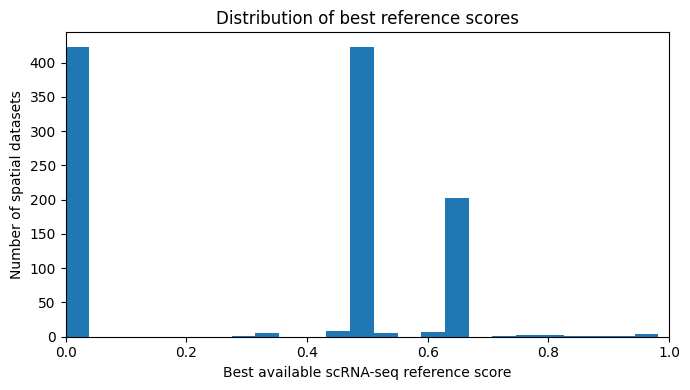

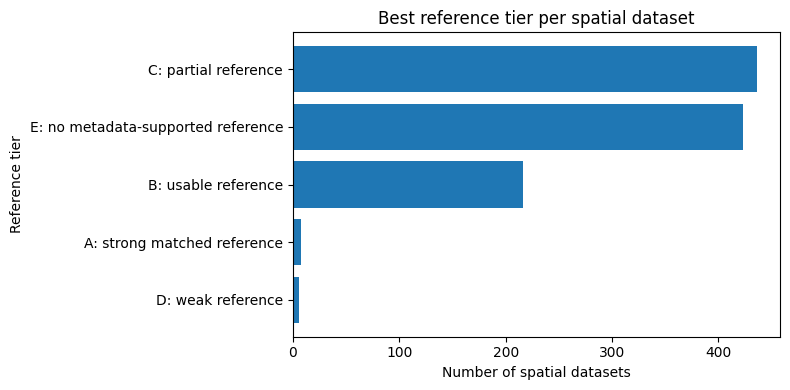

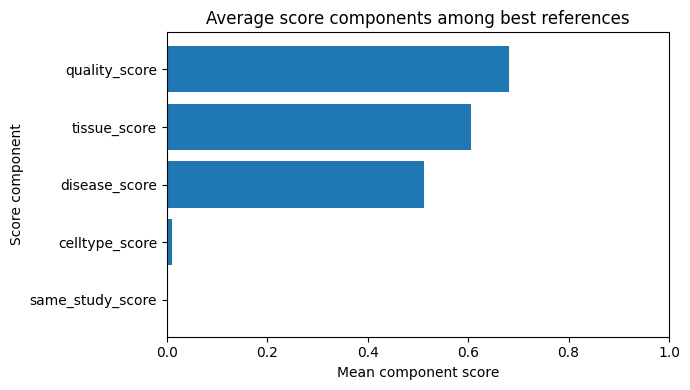

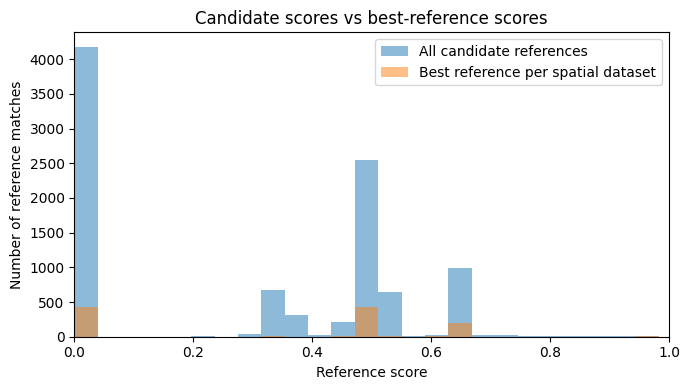

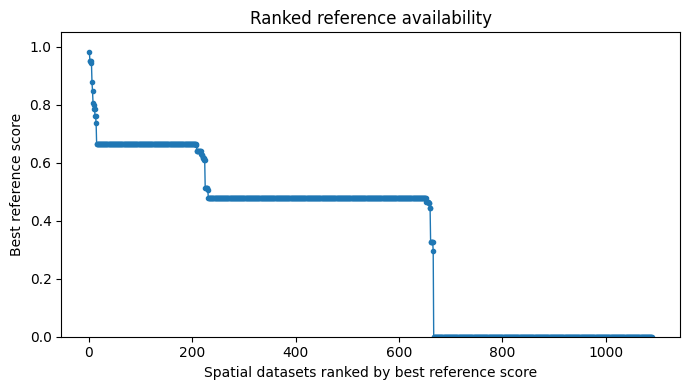

In [20]:
best_refs = plot_reference_score_report(reference_scores)

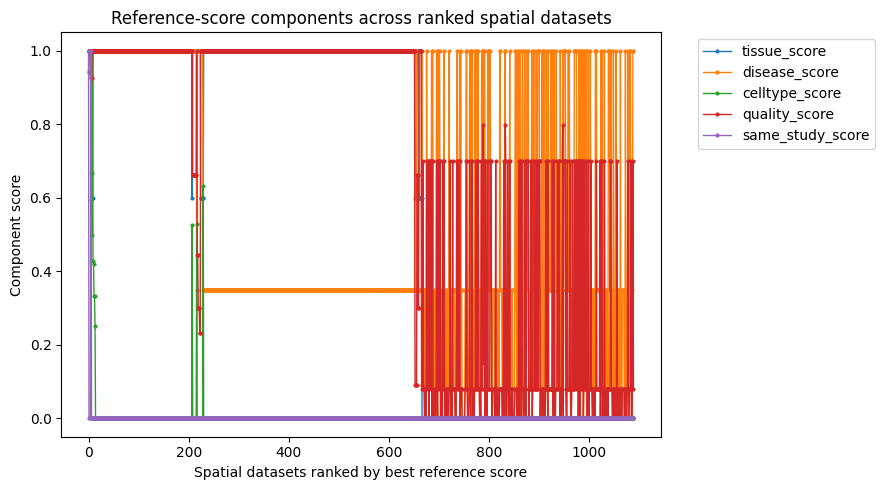

In [21]:
component_cols = [
    "tissue_score",
    "disease_score",
    "celltype_score",
    "quality_score",
    "same_study_score",
]

ranked = best_refs.sort_values("score", ascending=False).reset_index(drop=True)

plt.figure(figsize=(9, 5))

for col in component_cols:
    plt.plot(
        np.arange(len(ranked)),
        ranked[col],
        marker="o",
        markersize=2,
        linewidth=1,
        label=col,
    )

plt.xlabel("Spatial datasets ranked by best reference score")
plt.ylabel("Component score")
plt.title("Reference-score components across ranked spatial datasets")
plt.ylim(-0.05, 1.05)
plt.legend(bbox_to_anchor=(1.05, 1), loc="upper left")
plt.tight_layout()
plt.show()

In [22]:
best_refs = best_refs.copy()

# Require at least broad biological evidence of reference relevance
best_refs["has_biological_match"] = (
    (best_refs["tissue_score"] > 0) |
    (best_refs["celltype_score"] > 0) |
    (best_refs["disease_score"] > 0)
)

best_refs["score_gated"] = best_refs["score"].where(
    best_refs["has_biological_match"],
    0.0
)

def score_to_tier_gated(score):
    if score >= 0.85:
        return "A: strong matched reference"
    elif score >= 0.65:
        return "B: usable reference"
    elif score >= 0.40:
        return "C: partial reference"
    elif score > 0:
        return "D: weak reference"
    else:
        return "E: no usable reference"

best_refs["tier_gated"] = best_refs["score_gated"].apply(score_to_tier_gated)

In [24]:
best_refs["has_tissue_match"] = best_refs["tissue_score"] > 0

best_refs["score_tissue_gated"] = best_refs["score"].where(
    best_refs["has_tissue_match"],
    0.0
)

best_refs["tier_tissue_gated"] = best_refs["score_tissue_gated"].apply(score_to_tier_gated)

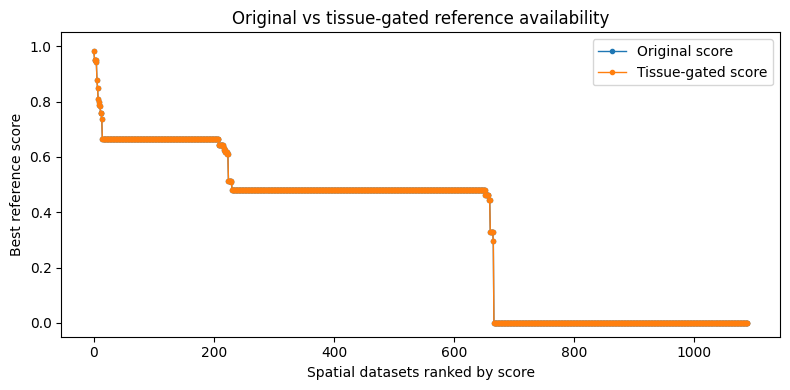

In [25]:
ranked = best_refs.sort_values("score", ascending=False).reset_index(drop=True)
ranked_gated = best_refs.sort_values("score_tissue_gated", ascending=False).reset_index(drop=True)

plt.figure(figsize=(8, 4))

plt.plot(
    np.arange(len(ranked)),
    ranked["score"],
    marker="o",
    markersize=3,
    linewidth=1,
    label="Original score",
)

plt.plot(
    np.arange(len(ranked_gated)),
    ranked_gated["score_tissue_gated"],
    marker="o",
    markersize=3,
    linewidth=1,
    label="Tissue-gated score",
)

plt.xlabel("Spatial datasets ranked by score")
plt.ylabel("Best reference score")
plt.title("Original vs tissue-gated reference availability")
plt.ylim(-0.05, 1.05)
plt.legend()
plt.tight_layout()
plt.show()

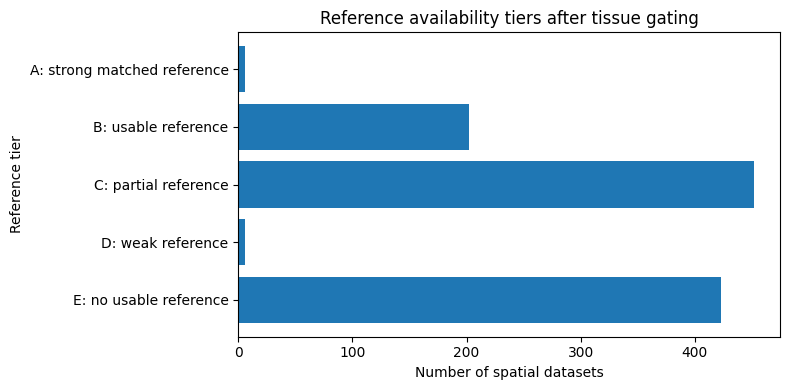

In [26]:
tier_order = [
    "A: strong matched reference",
    "B: usable reference",
    "C: partial reference",
    "D: weak reference",
    "E: no usable reference",
]

tier_counts = (
    best_refs["tier_tissue_gated"]
    .value_counts()
    .reindex(tier_order)
    .fillna(0)
)

plt.figure(figsize=(8, 4))
plt.barh(tier_counts.index[::-1], tier_counts.values[::-1])
plt.xlabel("Number of spatial datasets")
plt.ylabel("Reference tier")
plt.title("Reference availability tiers after tissue gating")
plt.tight_layout()
plt.show()

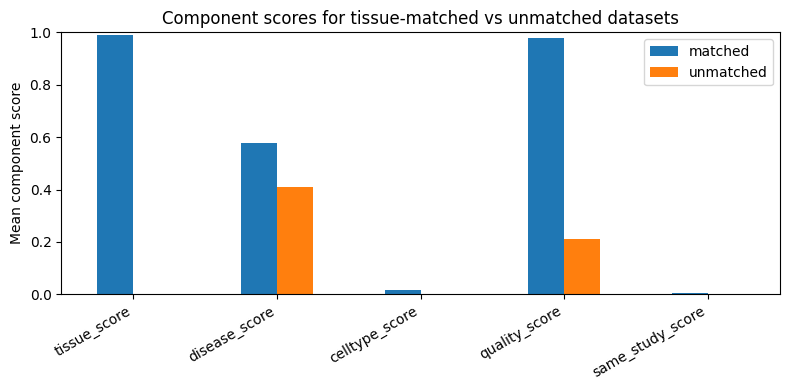

In [27]:
component_cols = [
    "tissue_score",
    "disease_score",
    "celltype_score",
    "quality_score",
    "same_study_score",
]

matched = best_refs[best_refs["score_tissue_gated"] > 0].copy()
unmatched = best_refs[best_refs["score_tissue_gated"] == 0].copy()

component_compare = pd.DataFrame({
    "matched": matched[component_cols].mean(),
    "unmatched": unmatched[component_cols].mean(),
})

ax = component_compare.plot(kind="bar", figsize=(8, 4))
ax.set_ylabel("Mean component score")
ax.set_title("Component scores for tissue-matched vs unmatched datasets")
ax.set_ylim(0, 1)
plt.xticks(rotation=30, ha="right")
plt.tight_layout()
plt.show()

In [28]:
dropped = best_refs[
    (best_refs["score"] > 0) &
    (best_refs["score_tissue_gated"] == 0)
].copy()

dropped[
    [
        "spatial_dataset_id",
        "ref_dataset_id",
        "ref_dataset_title",
        "ref_collection_name",
        "score",
        "score_tissue_gated",
        "tissue_score",
        "disease_score",
        "celltype_score",
        "quality_score",
        "same_study_score",
        "ref_n_cells",
        "ref_n_donors",
    ]
].sort_values("score", ascending=False).head(30)

,spatial_dataset_id,ref_dataset_id,ref_dataset_title,ref_collection_name,score,score_tissue_gated,tissue_score,disease_score,celltype_score,quality_score,same_study_score,ref_n_cells,ref_n_donors


In [29]:
datasets.columns

Index(['soma_joinid', 'citation', 'collection_id', 'collection_name',
       'collection_doi', 'collection_doi_label', 'dataset_id',
       'dataset_version_id', 'dataset_title', 'dataset_h5ad_path',
       'dataset_total_cell_count'],
      dtype='object')